## **ML LAB - 4**
### **Name - Shubhi Kumari**
### **Section - C_C3_34**

## Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

## Data Loading

In [ ]:
red_df = pd.read_csv("winequality-red.csv", sep=";")
white_df = pd.read_csv("winequality-white.csv", sep=";")

print("Red Wine Dataset:")
print(red_df.head())

print("\nWhite Wine Dataset:")
print(white_df.head())

Red Wine Dataset:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2 

## Data Concatenation

In [ ]:
red_df["wine_type"] = "red"
white_df["wine_type"] = "white"

df = pd.concat([red_df, white_df], ignore_index=True)

print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality wine_type  
0      9.4        5       red  
1      9.8        5   

## Initial Data Inspection

In [ ]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white


In [ ]:
df.shape

(6497, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
df.duplicated().sum()

np.int64(1177)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5320, 13)


## Feature Encoding

In [ ]:
le = LabelEncoder()

df["wine_type"] = le.fit_transform(df["wine_type"])

print(dict(zip(le.classes_, le.transform(le.classes_))))

df.head()

{'red': np.int64(0), 'white': np.int64(1)}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


## Box Plots of Features

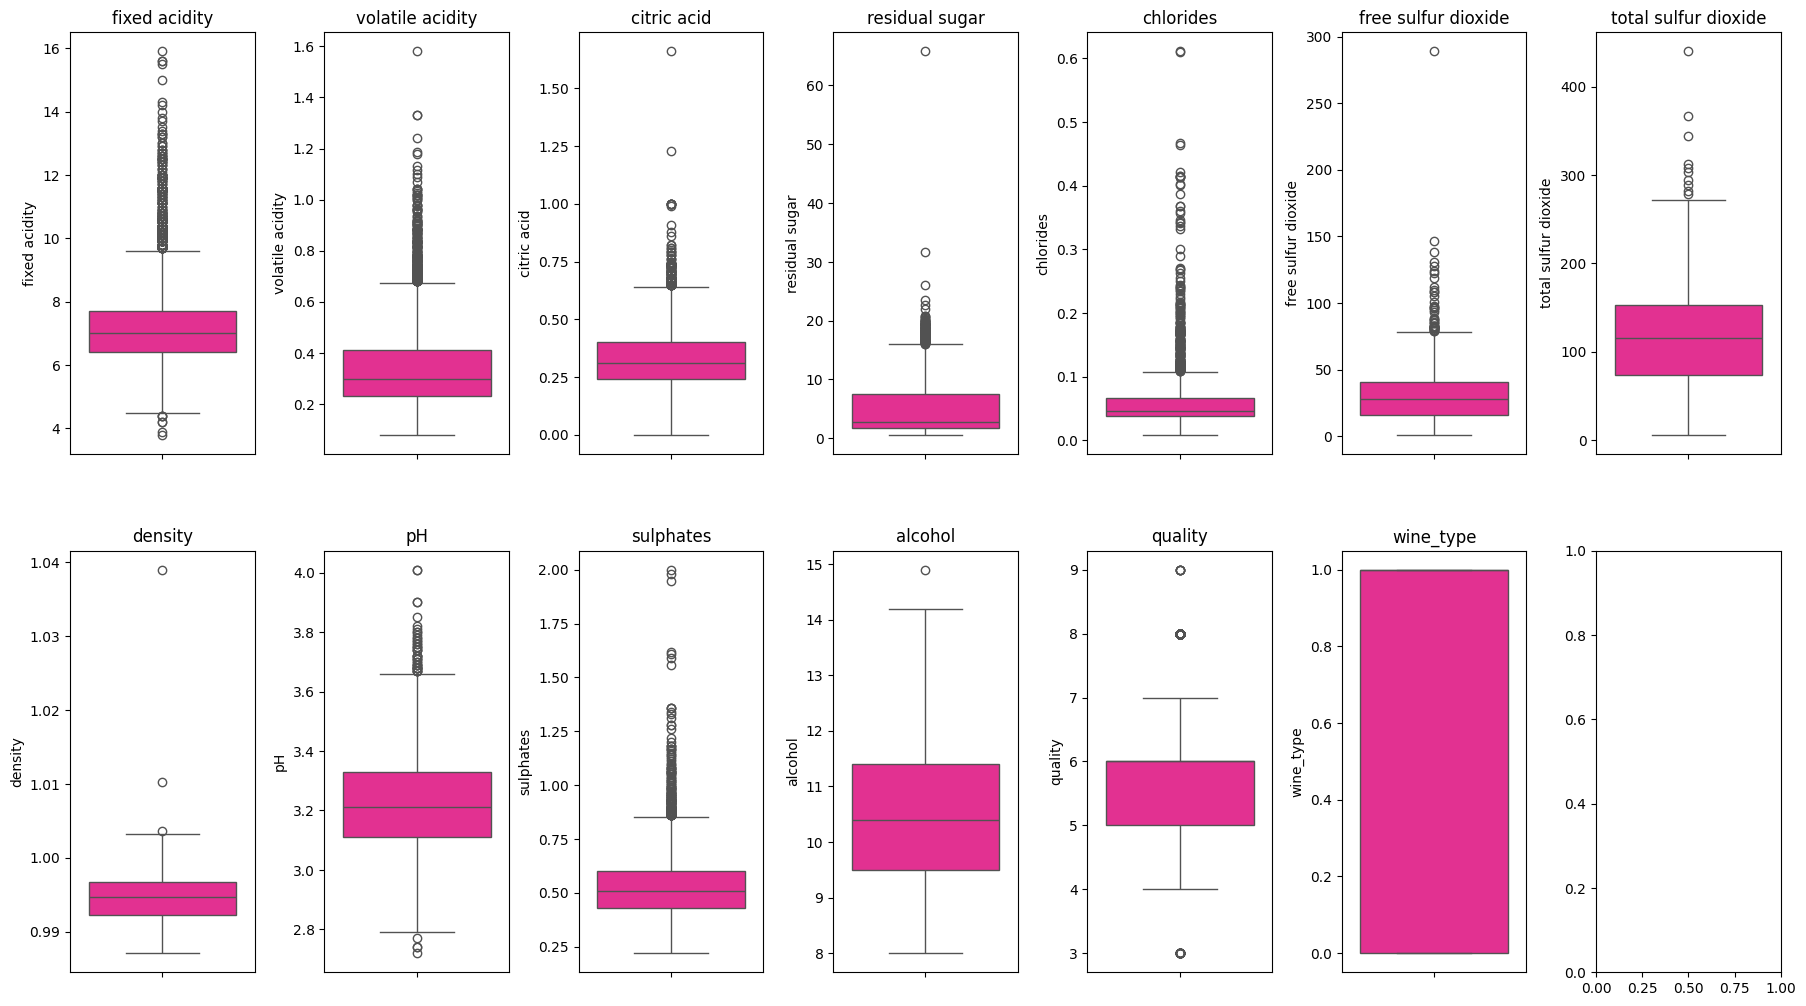

In [ ]:
features = df.select_dtypes(include=np.number)

fig, ax = plt.subplots(ncols=7, nrows=2, figsize=(18,10))

index = 0
ax = ax.flatten()

for col, value in features.items():
    sns.boxplot(y=value, ax=ax[index], color="deeppink")
    ax[index].set_title(col)
    index += 1

plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()

## Bar Plots: Features vs Quality

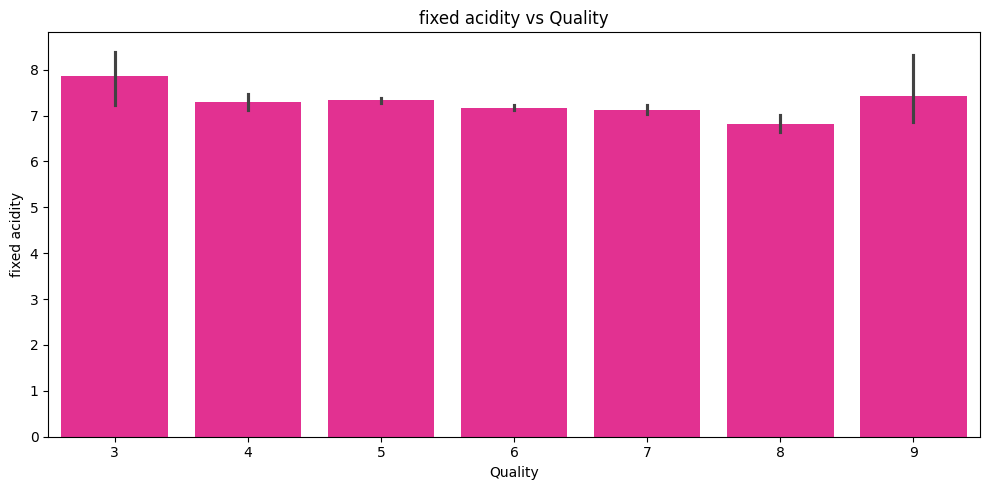

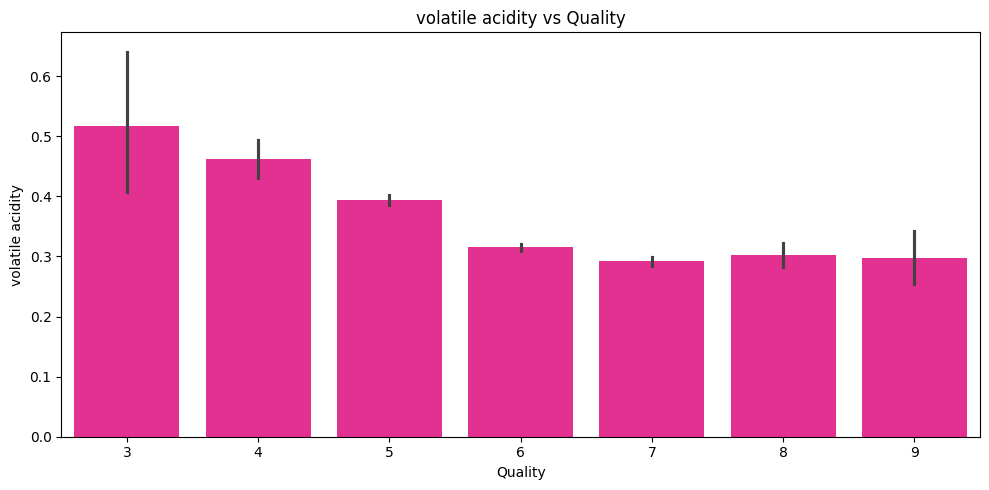

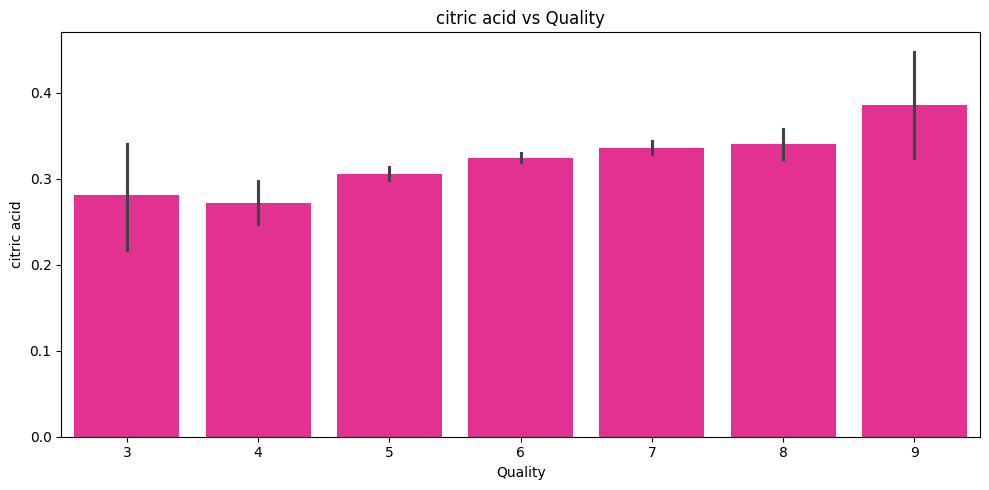

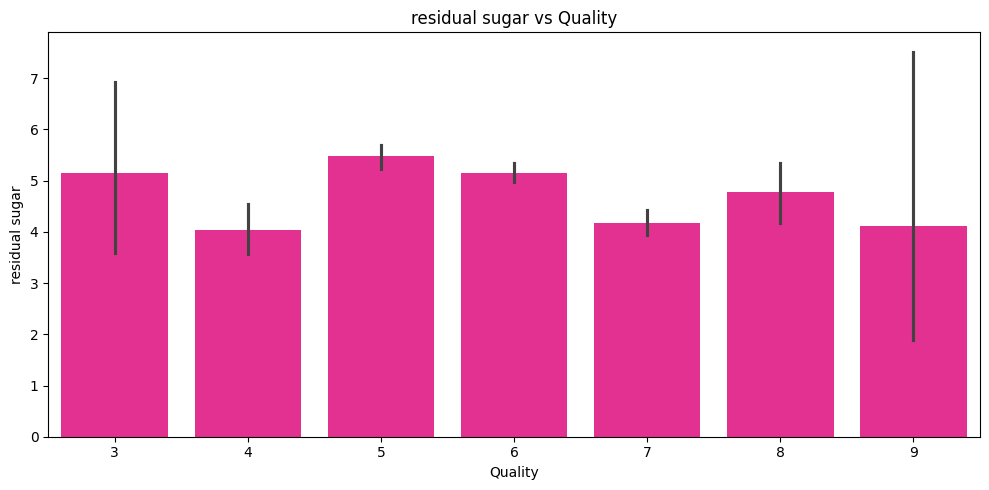

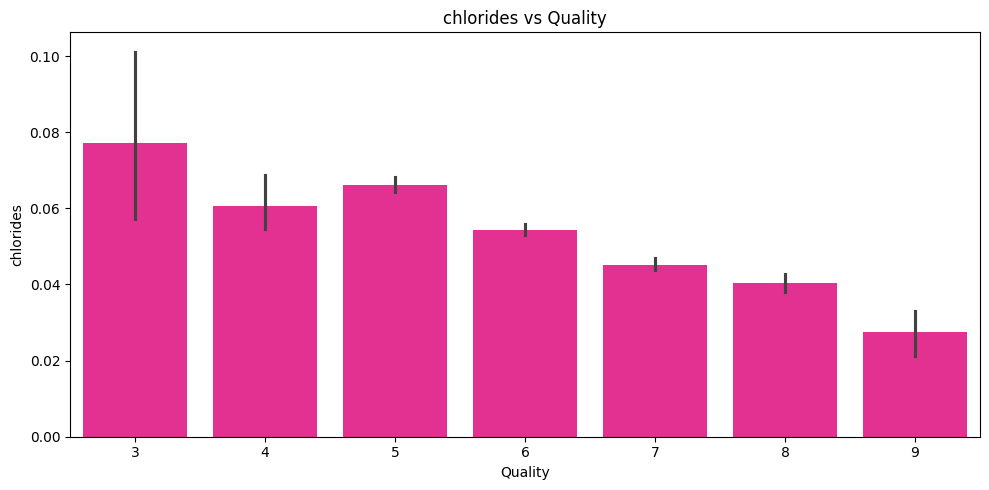

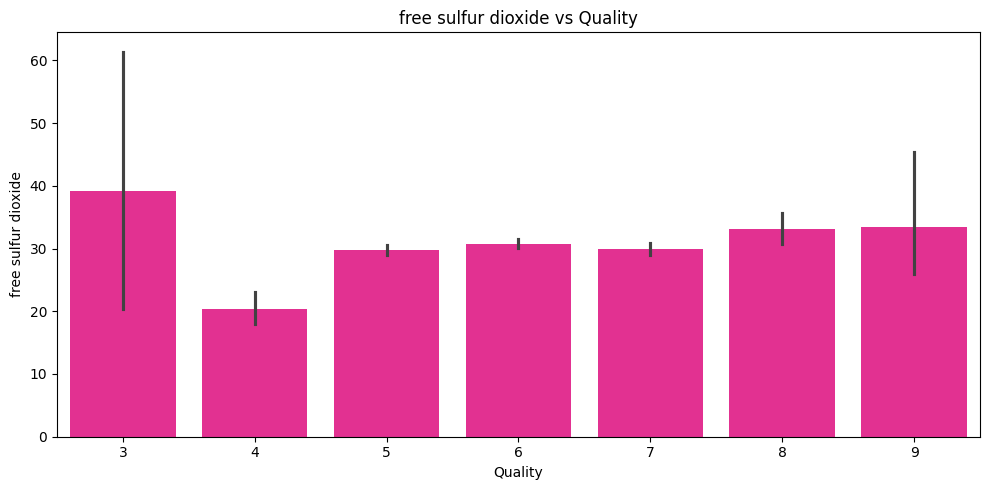

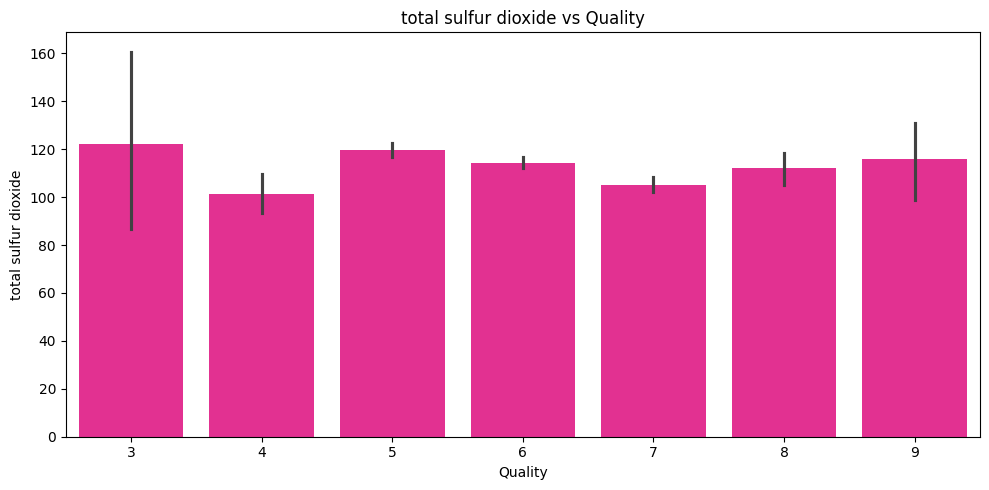

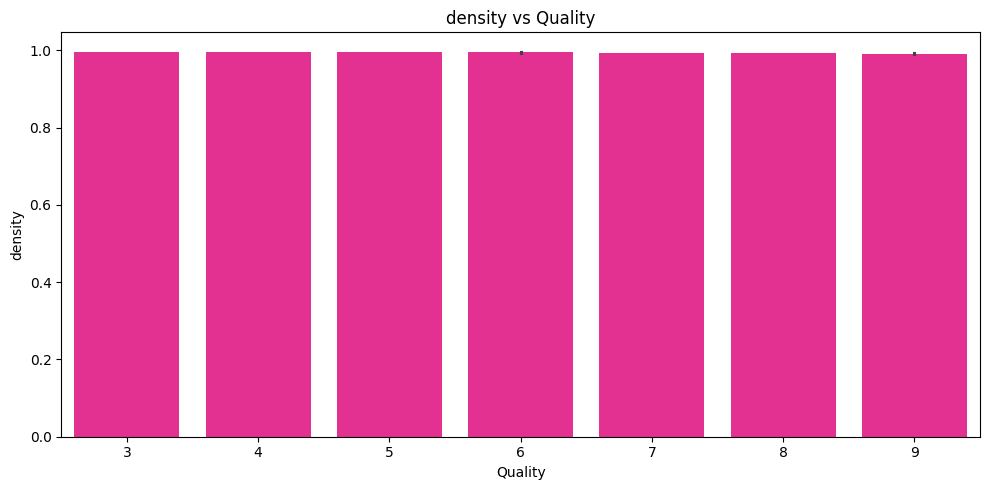

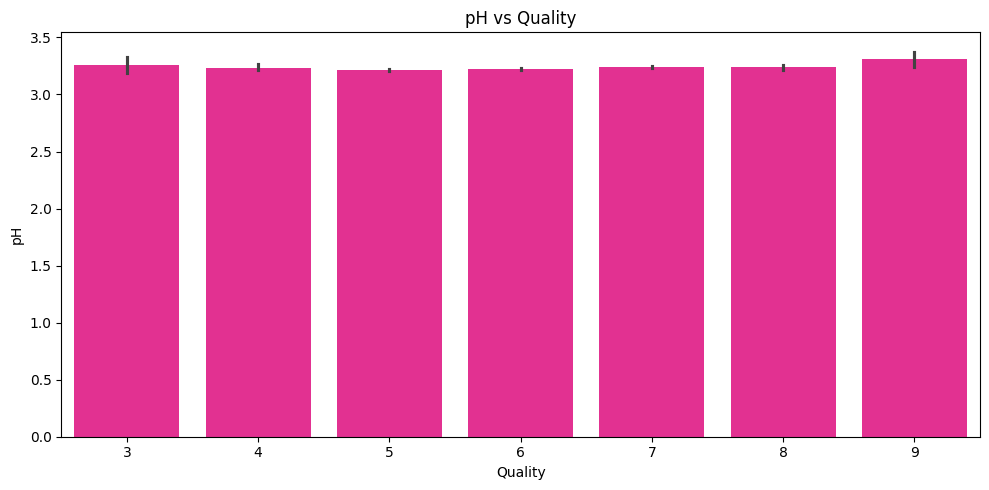

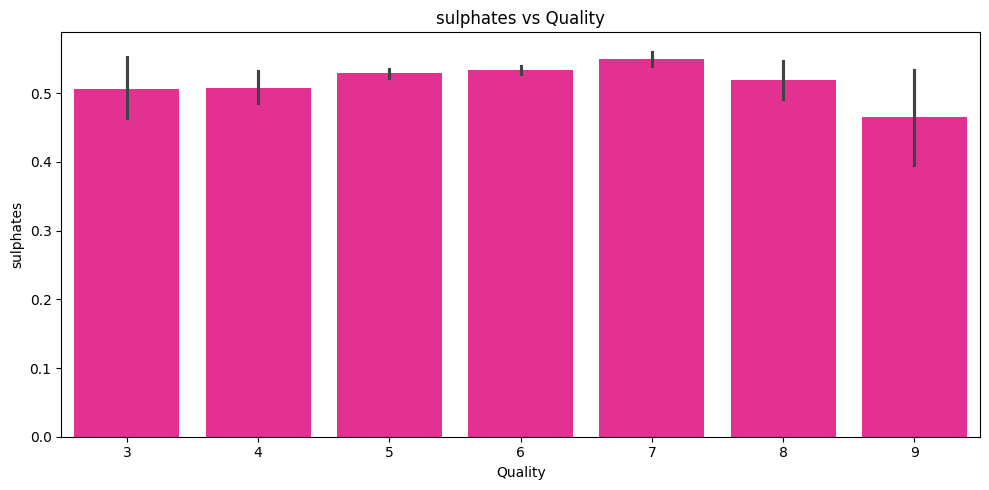

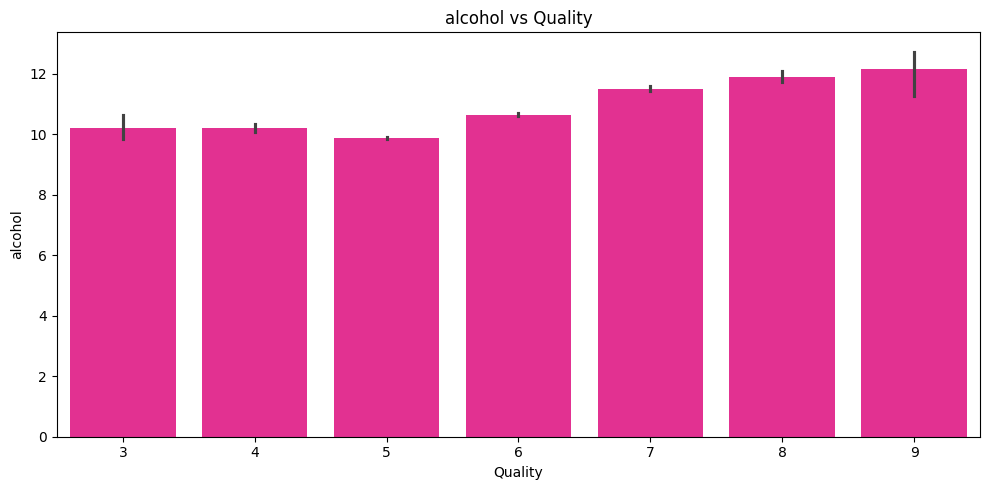

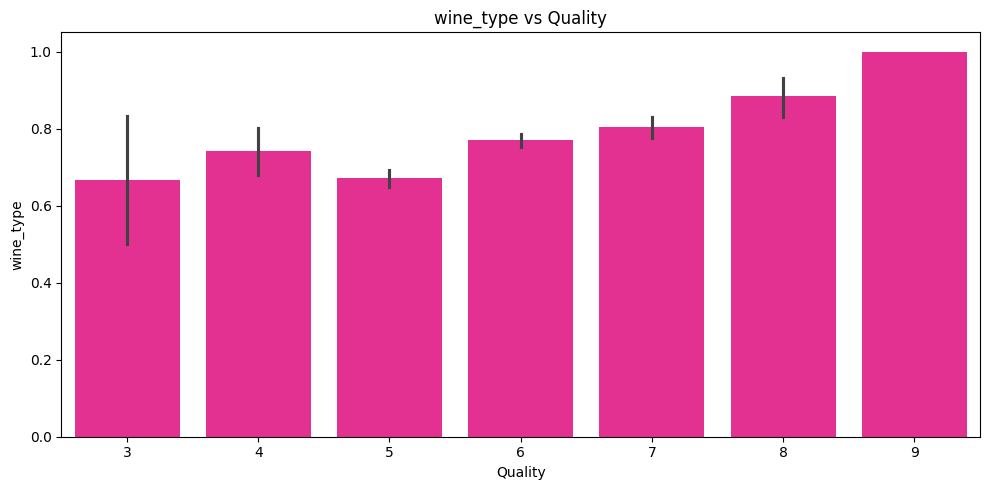

In [ ]:
index = 0

labels = df["quality"]

features = df.drop("quality", axis=1)

for col in features.columns:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=labels,
        y=features[col],
        data=df,
        color="deeppink"
    )

    plt.title(f"{col} vs Quality")
    plt.xlabel("Quality")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

## Scatter Plots: Features vs Quality

<Axes: xlabel='fixed acidity', ylabel='quality'>

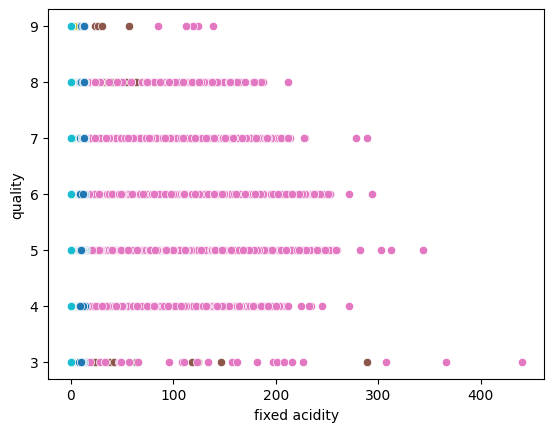

In [ ]:
sns.scatterplot(x="fixed acidity", y="quality", data=df)
sns.scatterplot(x="volatile acidity", y="quality", data=df)
sns.scatterplot(x="citric acid", y="quality", data=df)
sns.scatterplot(x="residual sugar", y="quality", data=df)
sns.scatterplot(x="chlorides", y="quality", data=df)
sns.scatterplot(x="free sulfur dioxide", y="quality", data=df)
sns.scatterplot(x="total sulfur dioxide", y="quality", data=df)
sns.scatterplot(x="density", y="quality", data=df)
sns.scatterplot(x="pH", y="quality", data=df)
sns.scatterplot(x="sulphates", y="quality", data=df)
sns.scatterplot(x="alcohol", y="quality", data=df)

## Pie Chart: Wine Type Distribution

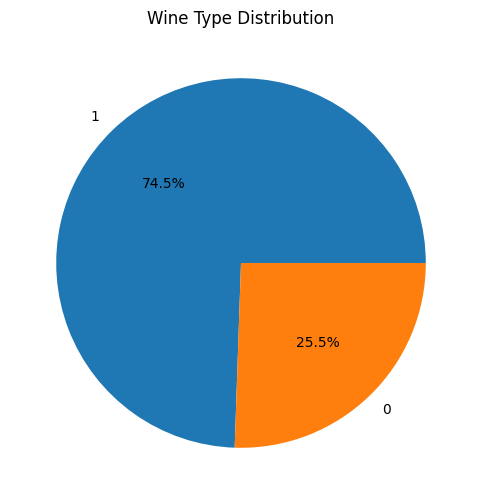

In [ ]:
wine_counts = df["wine_type"].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    wine_counts,
    labels=wine_counts.index,
    autopct="%1.1f%%"
)

plt.title("Wine Type Distribution")
plt.show()

## Histogram: Alcohol Distribution

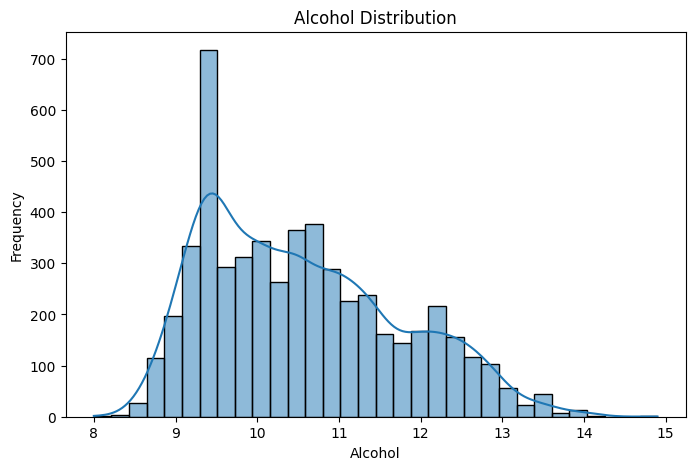

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["alcohol"], kde=True)

plt.title("Alcohol Distribution")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")

plt.show()

## Wine Quality Count

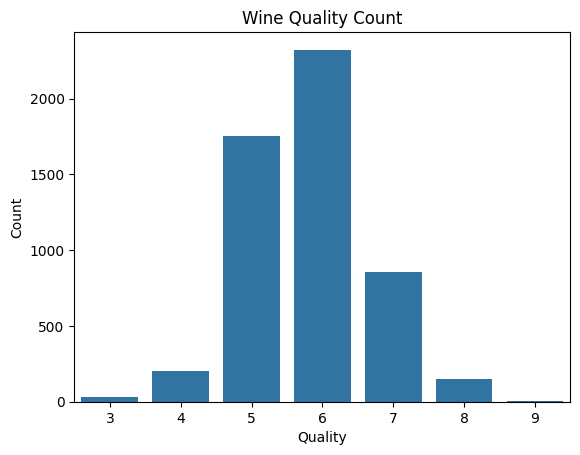

In [ ]:
sns.countplot(x="quality", data=df)

plt.title("Wine Quality Count")
plt.xlabel("Quality")
plt.ylabel("Count")

plt.show()

## Wine Type vs Quality

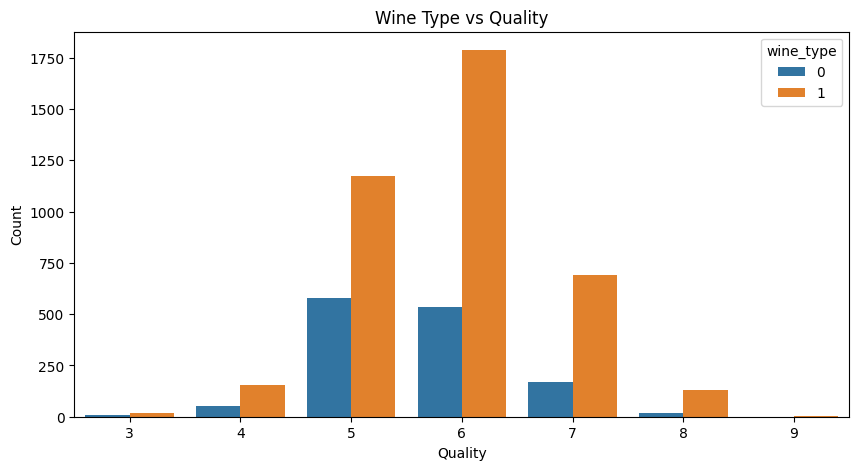

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(x="quality", hue="wine_type", data=df)

plt.title("Wine Type vs Quality")
plt.xlabel("Quality")
plt.ylabel("Count")

plt.show()

## Correlation Heatmap

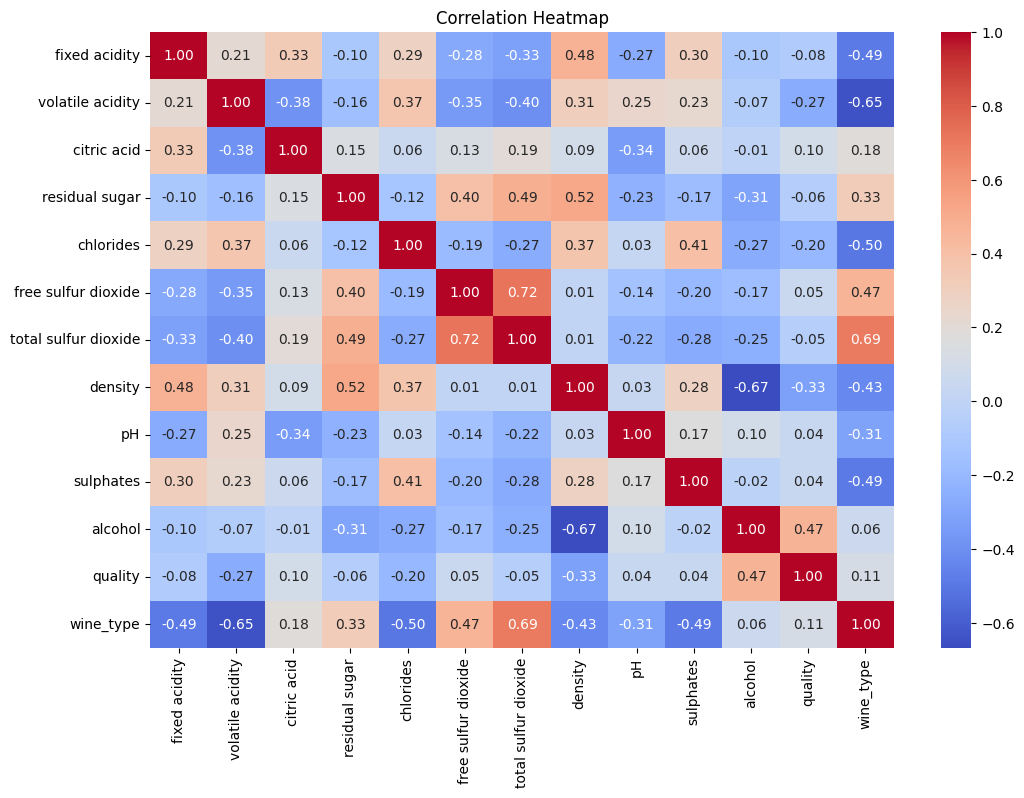

In [ ]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## Pair Plot

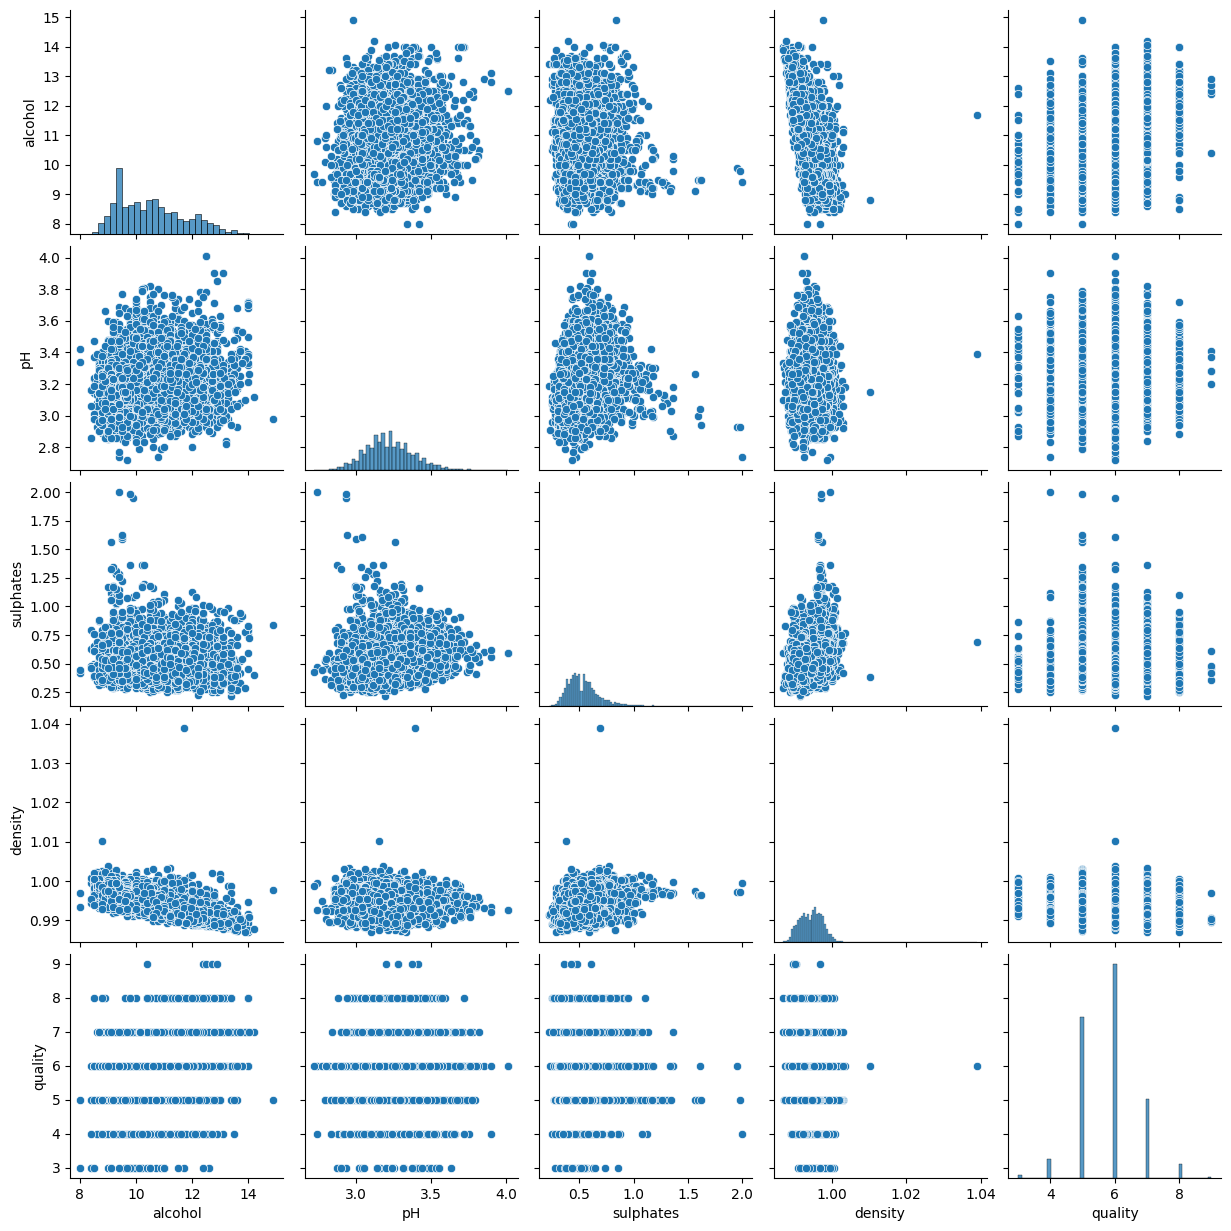

In [ ]:
sns.pairplot(
    df[["alcohol", "pH", "sulphates", "density", "quality"]]
)

plt.show()

## Distribution Plots

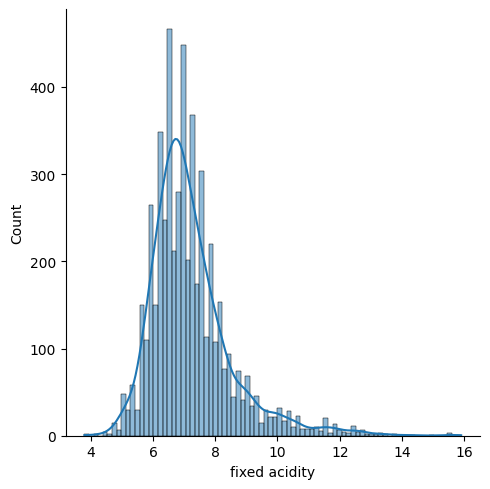

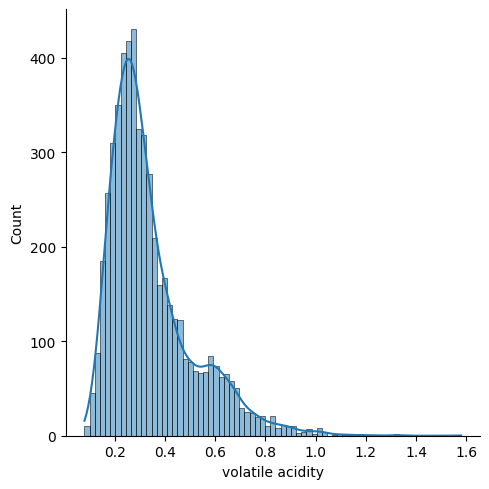

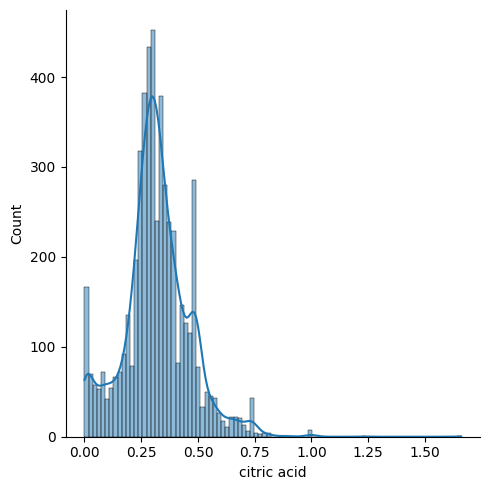

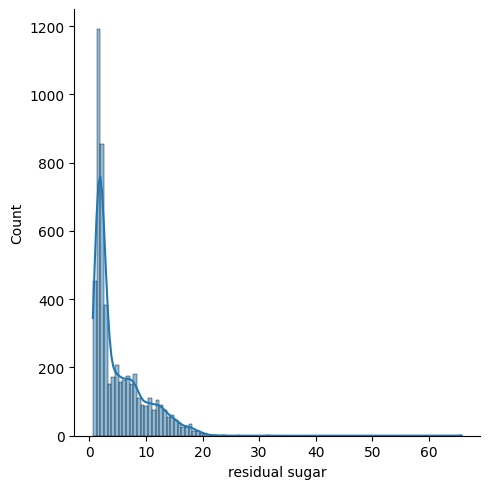

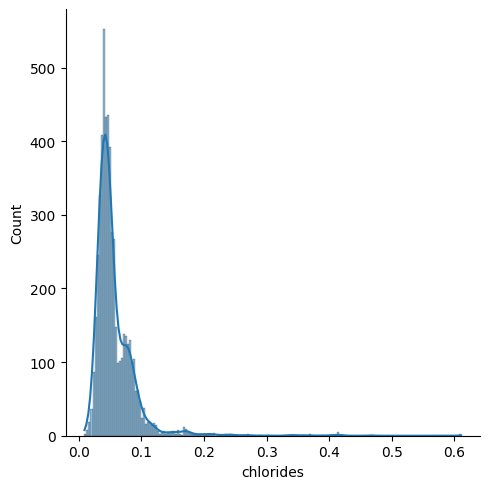

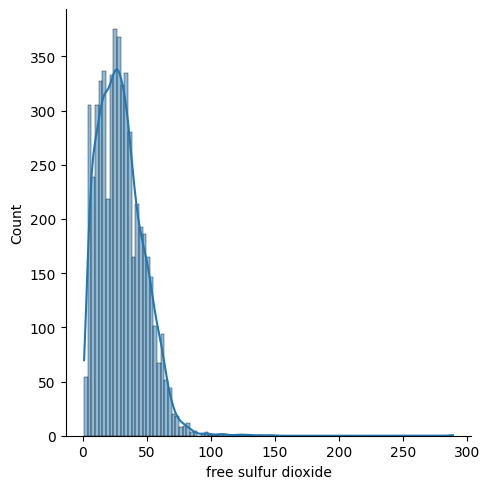

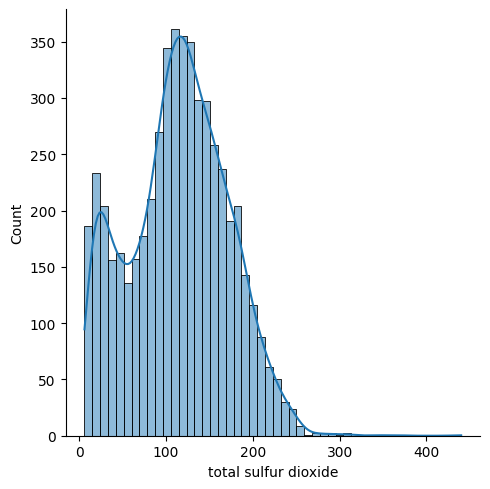

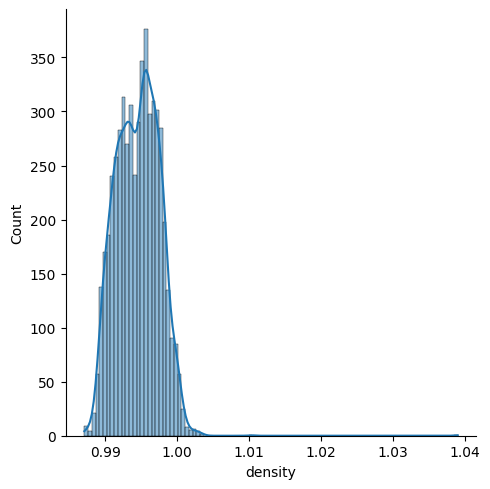

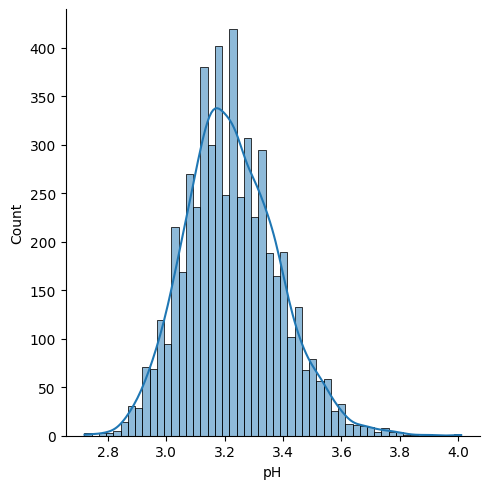

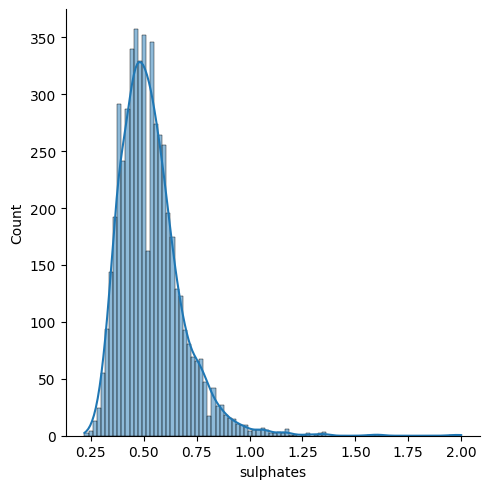

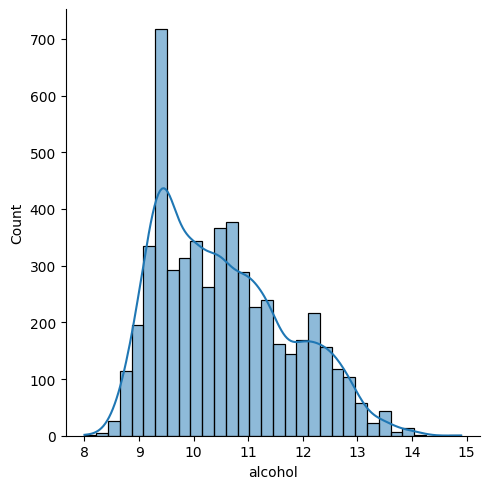

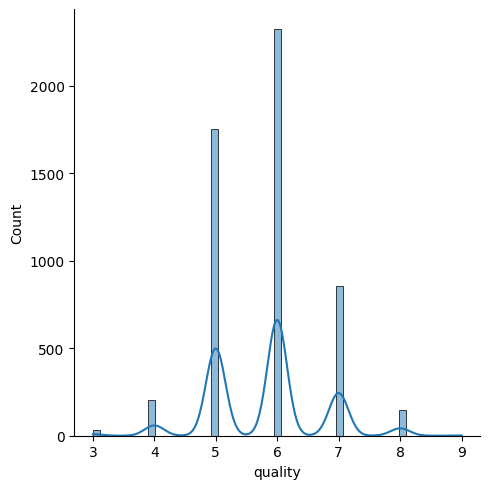

In [ ]:
sns.displot(df["fixed acidity"], kde=True)
sns.displot(df["volatile acidity"], kde=True)
sns.displot(df["citric acid"], kde=True)
sns.displot(df["residual sugar"], kde=True)
sns.displot(df["chlorides"], kde=True)
sns.displot(df["free sulfur dioxide"], kde=True)
sns.displot(df["total sulfur dioxide"], kde=True)
sns.displot(df["density"], kde=True)
sns.displot(df["pH"], kde=True)
sns.displot(df["sulphates"], kde=True)
sns.displot(df["alcohol"], kde=True)
sns.displot(df["quality"], kde=True)
plt.show()

### Feature Scaling: Standardizing Numerical Features

In [ ]:
features = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

scaler = StandardScaler()

df[features] = scaler.fit_transform(df[features])

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,0.140064,2.115349,-2.164515,-0.699699,0.523880,-1.069272,-1.411143,1.100996,1.779304,0.177941,-0.969152,5,0
1,0.443199,3.185297,-2.164515,-0.544135,1.120736,-0.282905,-0.829839,0.763753,-0.153797,0.979389,-0.631833,5,0
2,0.443199,2.471998,-1.892672,-0.610806,0.957957,-0.844596,-1.058837,0.831202,0.220351,0.779027,-0.631833,5,0
3,3.019841,-0.381197,1.641293,-0.699699,0.496751,-0.732258,-0.953146,1.168444,-0.403229,0.311515,-0.631833,6,0
4,0.140064,1.877583,-2.164515,-0.721923,0.496751,-0.956934,-1.305451,1.100996,1.779304,0.177941,-0.969152,5,0


## Data Splitting

In [ ]:
X = df.drop("quality", axis=1)

y = df["quality"]

print("X:")
print(X.head())

print("\ny:")
print(y.head())

X:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0       0.140064          2.115349    -2.164515       -0.699699   0.523880   
1       0.443199          3.185297    -2.164515       -0.544135   1.120736   
2       0.443199          2.471998    -1.892672       -0.610806   0.957957   
3       3.019841         -0.381197     1.641293       -0.699699   0.496751   
4       0.140064          1.877583    -2.164515       -0.721923   0.496751   

   free sulfur dioxide  total sulfur dioxide   density        pH  sulphates  \
0            -1.069272             -1.411143  1.100996  1.779304   0.177941   
1            -0.282905             -0.829839  0.763753 -0.153797   0.979389   
2            -0.844596             -1.058837  0.831202  0.220351   0.779027   
3            -0.732258             -0.953146  1.168444 -0.403229   0.311515   
4            -0.956934             -1.305451  1.100996  1.779304   0.177941   

    alcohol  wine_type  
0 -0.969152          0  
1 -

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (4256, 12)
X_test shape: (1064, 12)
y_train shape: (4256,)
y_test shape: (1064,)


## Model Evaluation Function

In [ ]:
def evaluate(name, model):
  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  acc = accuracy_score(y_test, pred)
  print(name, acc)
  print(classification_report(y_test, pred))
  cm = confusion_matrix(y_test, pred)
  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
  plt.title(name)
  plt.show()
  return model

## Decision Tree Classifier: Initial Training and Visualization (Max Depth 3)

Original 0.462406015037594
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.13      0.16      0.14        38
           5       0.52      0.56      0.54       348
           6       0.51      0.47      0.49       458
           7       0.40      0.39      0.40       190
           8       0.06      0.08      0.07        25
           9       0.00      0.00      0.00         1

    accuracy                           0.46      1064
   macro avg       0.23      0.24      0.23      1064
weighted avg       0.47      0.46      0.46      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


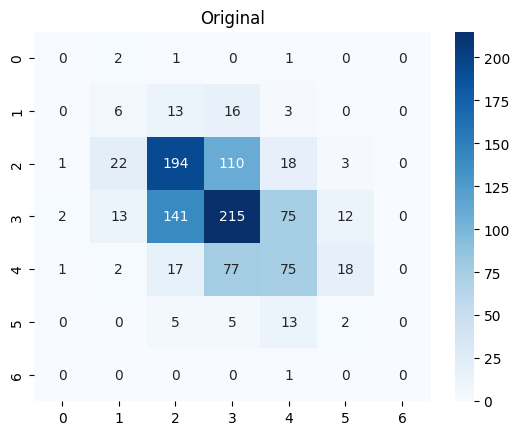

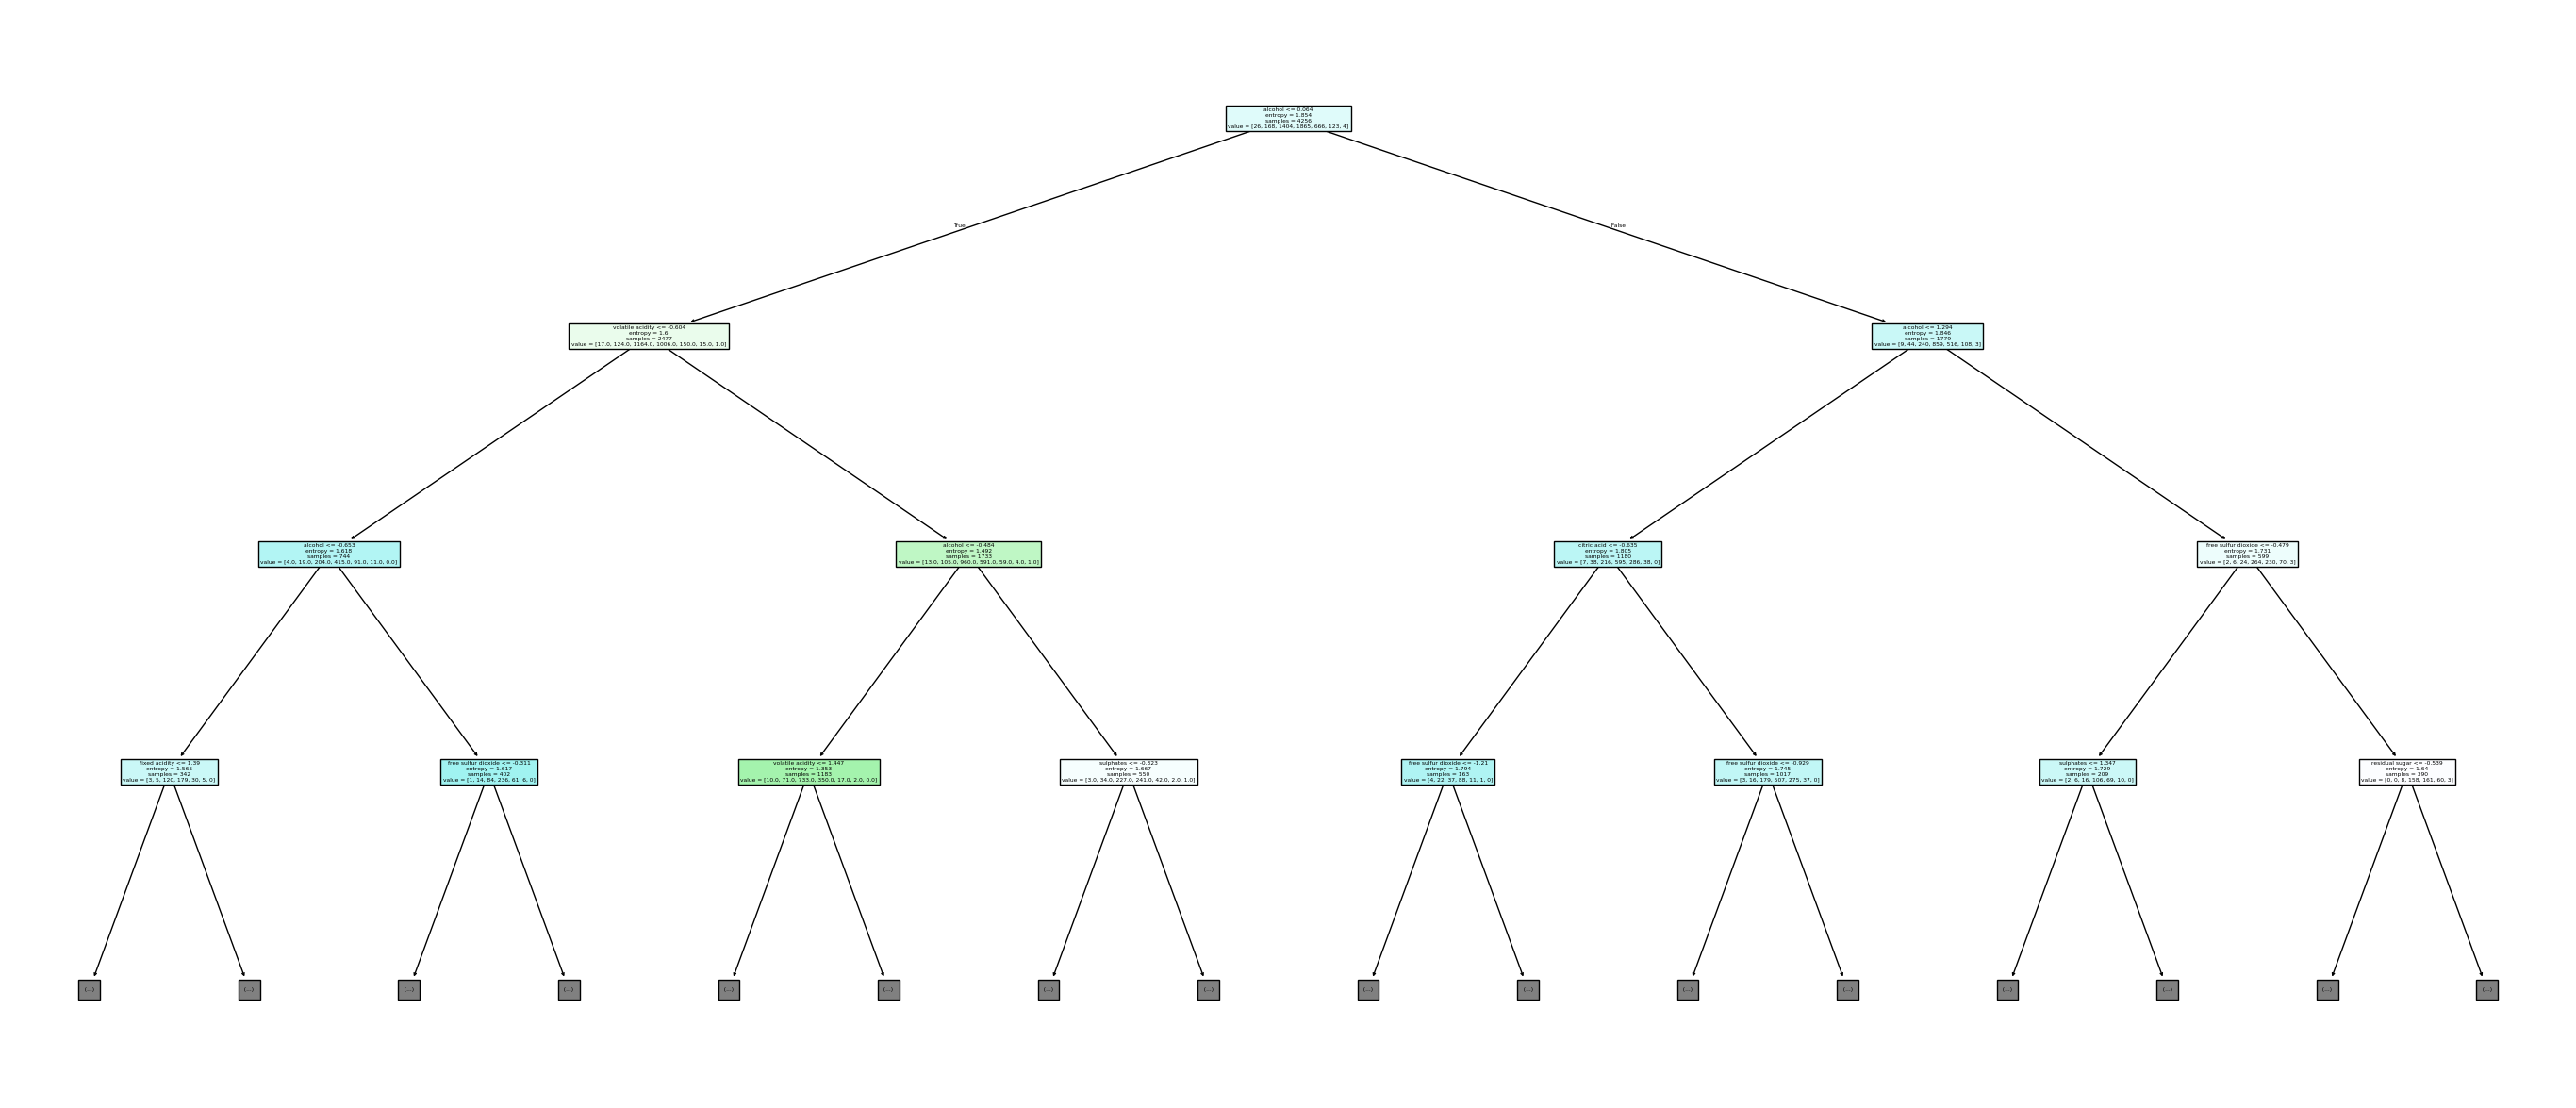

In [ ]:
tree = evaluate('Original', DecisionTreeClassifier(criterion='entropy', random_state=42))
plt.figure(figsize=(35,15))
plot_tree(tree, feature_names=X.columns, filled=True, max_depth=3)
plt.show()

### Decision Tree Classifier Visualization (Max Depth 4)

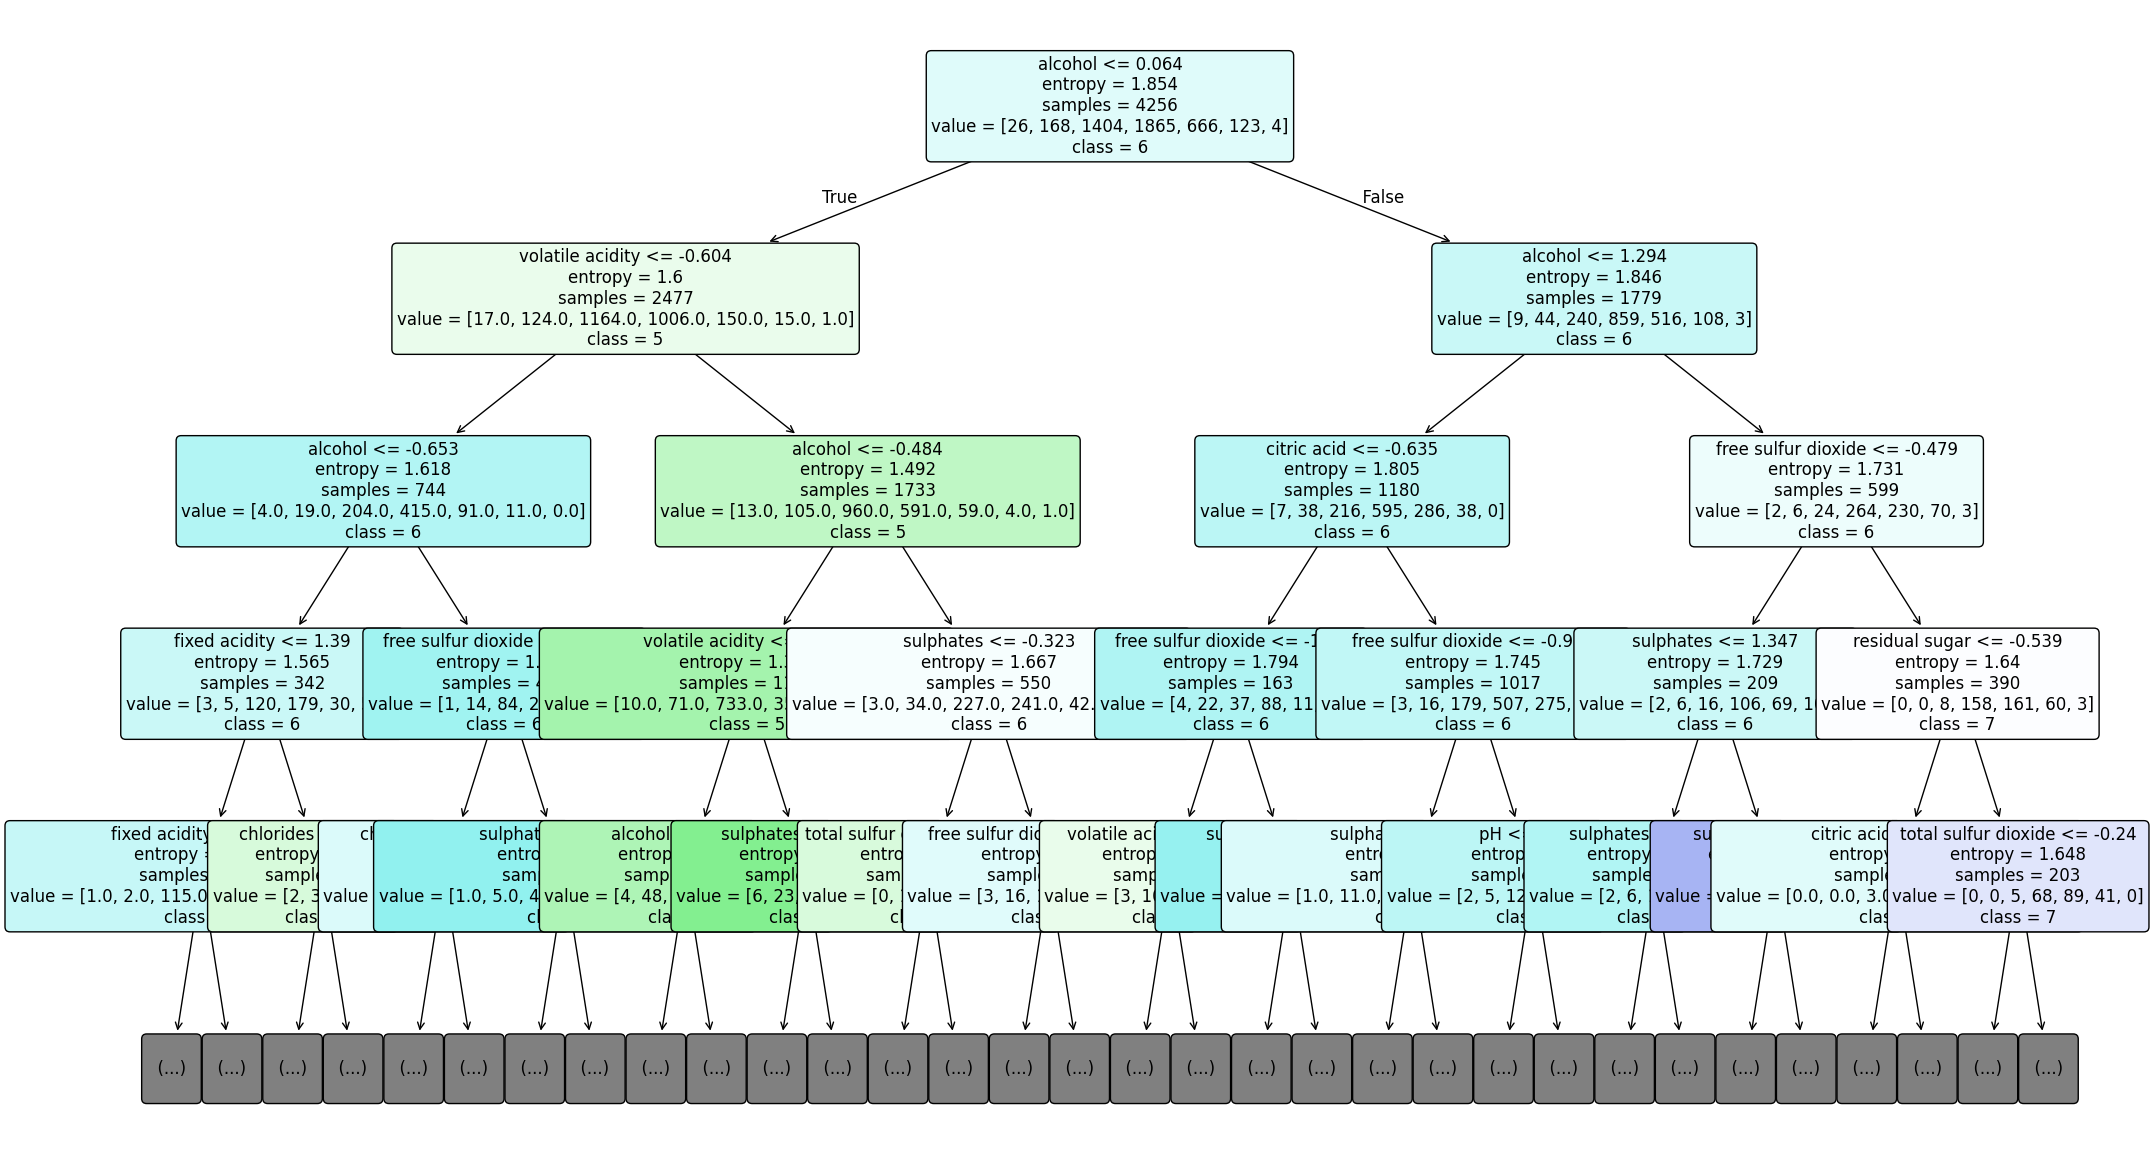

In [ ]:
plt.figure(figsize=(25, 15))
plot_tree(tree,
          feature_names=X.columns,
          class_names=[str(i) for i in sorted(y.unique())],
          filled=True,
          rounded=True,
          fontsize=12,
          max_depth=4
          )
plt.show()

In [ ]:
import pandas as pd

importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)

alcohol                 0.162259
free sulfur dioxide     0.103613
total sulfur dioxide    0.092836
sulphates               0.091325
volatile acidity        0.088874
pH                      0.085737
citric acid             0.080615
chlorides               0.075740
fixed acidity           0.075130
residual sugar          0.074155
density                 0.067914
wine_type               0.001801
dtype: float64


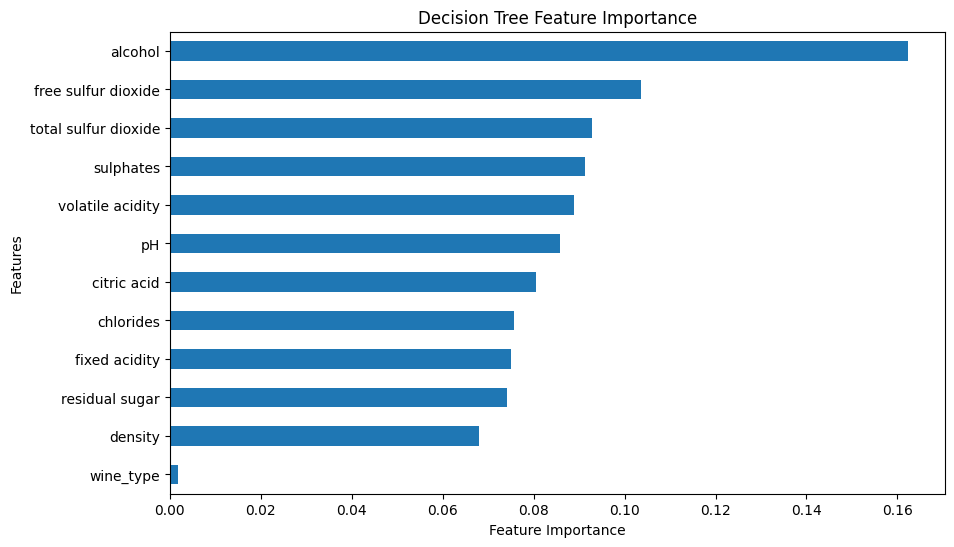

In [ ]:
plt.figure(figsize=(10,6))
importance.sort_values().plot(kind='barh')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Decision Tree Feature Importance')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

# Calculate training accuracy
train_pred = tree.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)

# Calculate testing accuracy
test_pred = tree.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.462406015037594


MaxDepth=2 0.5075187969924813
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00        38
           5       0.55      0.70      0.61       348
           6       0.48      0.64      0.55       458
           7       0.00      0.00      0.00       190
           8       0.00      0.00      0.00        25
           9       0.00      0.00      0.00         1

    accuracy                           0.51      1064
   macro avg       0.15      0.19      0.17      1064
weighted avg       0.38      0.51      0.44      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


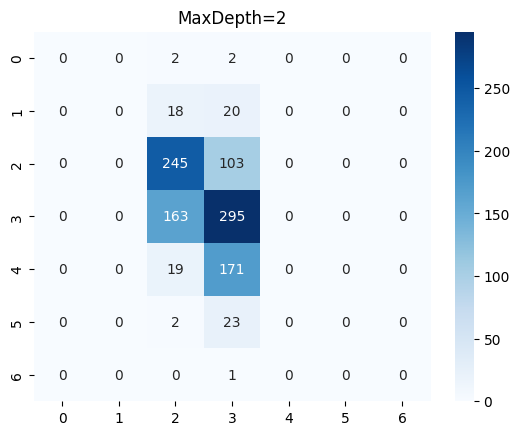

MaxDepth=3 0.5385338345864662
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00        38
           5       0.63      0.56      0.59       348
           6       0.50      0.72      0.59       458
           7       0.51      0.25      0.34       190
           8       0.00      0.00      0.00        25
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1064
   macro avg       0.23      0.22      0.22      1064
weighted avg       0.51      0.54      0.51      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


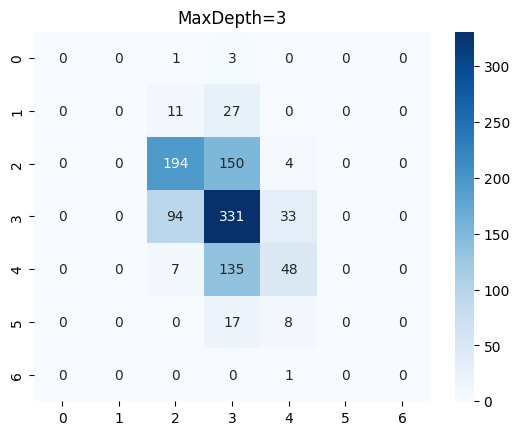

MaxDepth=4 0.5460526315789473
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00        38
           5       0.60      0.61      0.61       348
           6       0.51      0.72      0.60       458
           7       0.62      0.19      0.30       190
           8       0.00      0.00      0.00        25
           9       0.00      0.00      0.00         1

    accuracy                           0.55      1064
   macro avg       0.25      0.22      0.21      1064
weighted avg       0.53      0.55      0.51      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


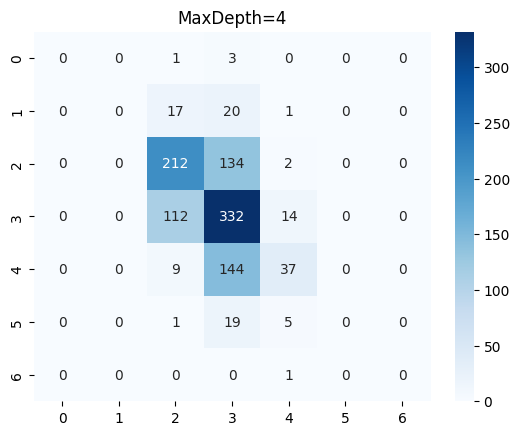

MaxDepth=5 0.5385338345864662
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00        38
           5       0.57      0.64      0.60       348
           6       0.51      0.69      0.59       458
           7       0.62      0.19      0.30       190
           8       0.00      0.00      0.00        25
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1064
   macro avg       0.24      0.22      0.21      1064
weighted avg       0.52      0.54      0.50      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


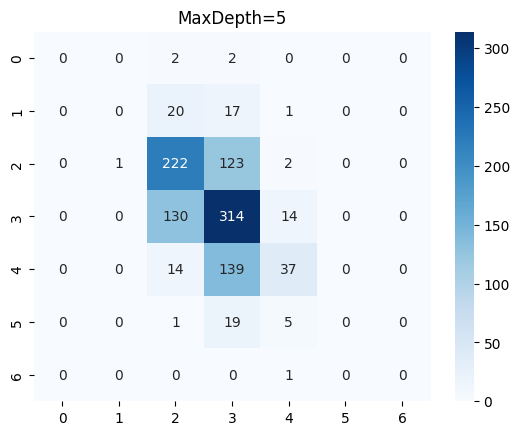

MaxDepth=None 0.462406015037594
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.13      0.16      0.14        38
           5       0.52      0.56      0.54       348
           6       0.51      0.47      0.49       458
           7       0.40      0.39      0.40       190
           8       0.06      0.08      0.07        25
           9       0.00      0.00      0.00         1

    accuracy                           0.46      1064
   macro avg       0.23      0.24      0.23      1064
weighted avg       0.47      0.46      0.46      1064



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


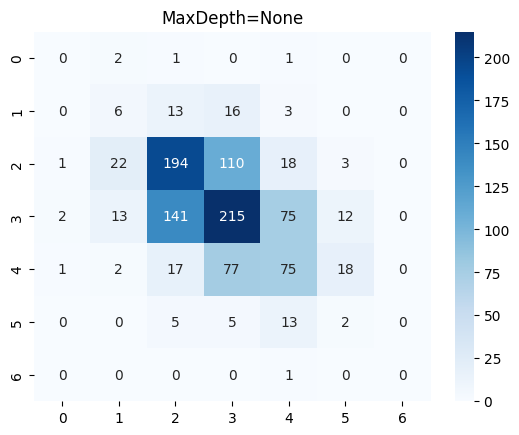

In [ ]:
for d in [2,3,4,5,None]:
  evaluate(f'MaxDepth={d}', DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42))

# **Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'ccp_alpha': [0, 0.001, 0.005, 0.01]
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy',
                    n_jobs = -1)

grid.fit(X_train, y_train)

print("Best Parameters")
print(grid.best_params_)

print("Best Cross Validation Accuracy")
print(grid.best_score_)

best_tree = grid.best_estimator_

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Best Parameters
{'ccp_alpha': 0.005, 'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross Validation Accuracy
0.530779585464215


In [ ]:
y_pred = best_tree.predict(X_test)

print(classification_report(y_test, y_pred))
print("Accuracy =", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00        38
           5       0.58      0.61      0.59       348
           6       0.50      0.67      0.57       458
           7       0.51      0.25      0.34       190
           8       0.00      0.00      0.00        25
           9       0.00      0.00      0.00         1

    accuracy                           0.53      1064
   macro avg       0.23      0.22      0.22      1064
weighted avg       0.50      0.53      0.50      1064

Accuracy = 0.5310150375939849


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# **Cross Validation**

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(best_tree, X, y, cv=10, scoring='accuracy')
print(scores)
print("Average Accuracy =", scores.mean())
print("Std =", scores.std())

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 5 members, which is less than n_splits=10.
  warnings.warn(


[0.42857143 0.56015038 0.46804511 0.4943609  0.57330827 0.4962406
 0.52819549 0.56203008 0.51879699 0.52255639]
Average Accuracy = 0.5152255639097745
Std = 0.04283446504606647


# **Learning Curve**

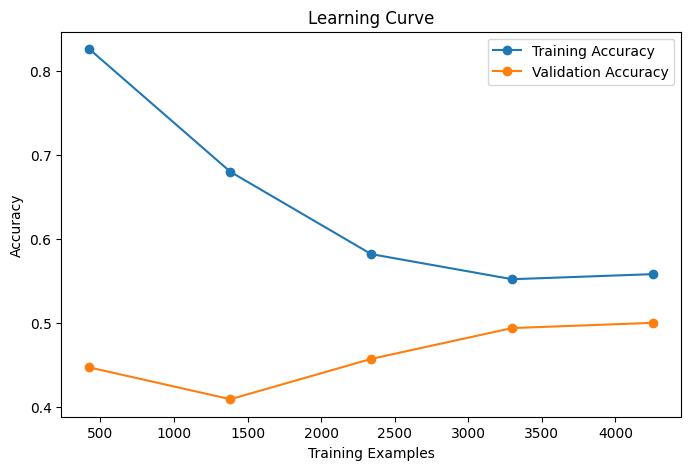

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    best_tree,
    X,
    y,
    cv=5,
    scoring='accuracy'
)
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training Accuracy')
plt.plot(train_sizes, test_scores.mean(axis=1), 'o-', label='Validation Accuracy')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.show()

# **Validation Curve**

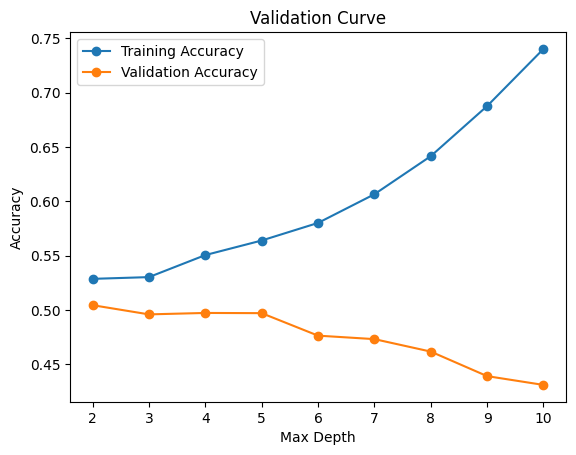

In [ ]:
from sklearn.model_selection import validation_curve

param_range=[2,3,4,5,6,7,8,9,10]
train_scores, test_scores = validation_curve(
    DecisionTreeClassifier(criterion='entropy', random_state=42),
    X,
    y,
    param_name = "max_depth", param_range= param_range, cv=5)

plt.plot(param_range, train_scores.mean(axis=1),'o-', label='Training Accuracy')
plt.plot(param_range, test_scores.mean(axis=1),'o-', label='Validation Accuracy')

plt.legend()
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.show()

# **Normalized Confusion Matrix**

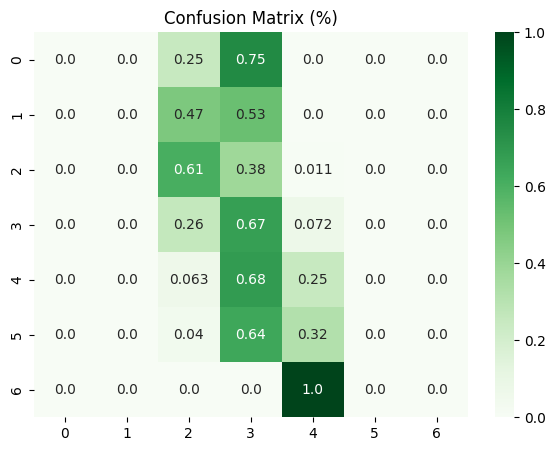

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm/cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_percent, annot=True, fmt=".2", cmap="Greens")
plt.title("Confusion Matrix (%)")
plt.show()